# p2.6: Phase 1's teaching result on the two-mode student (11/25/26)

*Part of phase 2: `p2_summary.ipynb` (section 10) connects this notebook with p2.1-p2.5.*

Phase 1's teaching results came from a student that played by intuition alone. Phase 2 replaced it with the two-mode
student (`spec.STUDENT`: AND-OR deliberation, flat planning and intuition drawn per move, on a start of two networks
with 2 lane blocks each). Do phase 1's results still hold? Phase 1 had two:
- **bayes4 beats no teacher at every agency** (ΔA, how much a shown move teaches; the student's own play is 1), by
  0.20-0.30 moves / optimal at the end of the session.
- **Showing every move goes from harmful to the best help as ΔA rises**: +0.75 at ΔA 0.1, −0.61 at ΔA 1, overtaking
  bayes4 between ΔA 0.5 and 0.7.

**The runs** (`experiments/replication_queue.py`): phase 1's ×10 agency sweep played again, with the same teachers per
ΔA (bayes4 alone at 0; no teacher, bayes4, random 30% and random 100% at 1; bayes4 and the two randoms in between), 8
students per run and seeds 0-2. Two students:
- **two-mode**: today's fitted student (`--fitted`), runs `twomode_m10[_s<seed>]_agency<a>`;
- **intuition, new start**: phase 1's way of playing on today's start (`--fitted --student intuition`), runs
  `intuition_m10[_s<seed>]_agency<a>`. It tells the change of start apart from the change of play.

Phase 1's own runs are `aostart_free_m10[_s<seed>]_agency<a>`.

Sections 1-10 replicate phase 1 and trace the students' difference to memory and loops. Sections 11-14 test two
ideas for those loops: a memory for which repeated returns grow more salient, and a bayes4 that notices loops.
Whether salience's parameter is needed, and its adoption into the student, are in `p2.7_feature_tests.ipynb`.

**The score** is phase 1's (`experiments/phase2_analysis.py`): the end test's moves / optimal, an unsolved puzzle
counted at its cap (10 × optimal), untaught and without giving up. Each teacher is compared with no teacher student by
student and pooled over seeds (24 students). No teacher runs only at ΔA 1, since it never sees a shown move. Tables:
`experiments/replication_analysis.py` → `models/summary/replication_{twomode,intuition}.csv`, beside phase 1's
`ao10_agency_seeds.csv`.

In [1]:
import os
import sys
sys.path.insert(0, "..")
sys.path.insert(0, os.path.join("..", "experiments"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import phase2_analysis as p2
import replication_analysis as ra
from rushhour import analysis as an

INK, MUTED, RULE, GRID = "#1f1f1d", "#5f5e5a", "#b5b4ad", "#e6e5e0"
STUDENTS = {"phase 1": p2.SEEDS, "intuition, new start": ra.seeds("intuition"), "two-mode": ra.seeds("twomode")}
TABLES = {"phase 1": "ao10_agency_seeds.csv", "intuition, new start": "replication_intuition.csv",
          "two-mode": "replication_twomode.csv"}
S_COLORS = {"phase 1": "#8a8a85", "intuition, new start": "#2a78d6", "two-mode": "#e6550d"}
TEACHERS = {"bayes4": "bayes4", "random:0.3": "random 30%", "random:1.0": "random 100%"}
T_COLORS = {"bayes4": INK, "random:0.3": "#fdae6b", "random:1.0": "#e6550d"}
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.titlelocation": "left", "figure.dpi": 110,
                     "legend.frameon": False, "legend.fontsize": 8.5})


def tidy(ax, grid="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(RULE)
    ax.tick_params(colors=MUTED)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


tables = {s: pd.read_csv(os.path.join(p2.SUMMARY, f)) for s, f in TABLES.items()}

# no teacher: each test of the session, per student, averaged over the 8 students of a run and then over seeds
rows = []
for student, seeds in STUDENTS.items():
    for seed, pattern in seeds.items():
        e = an.entry(pattern.format(p2.NONE_AT), "none")
        for s, by_n in e["results"].items():
            for n, attempts in by_n.items():
                score, solved, solved_ratio = an.measures(attempts, e["config"])
                rows.append({"student": student, "seed": seed, "id": s, "trial": int(n) // 10, "score": score,
                             "solved": solved, "moves / optimal (solved)": solved_ratio})
untaught = pd.DataFrame(rows)
none_end = untaught[untaught.trial == untaught.trial.max()].groupby("student").score.mean()

## 1. Each teacher against no teacher

The end score's difference from no teacher (negative: the teacher helped), pooled over seeds 0-2, ± 1 SE across the
24 students.

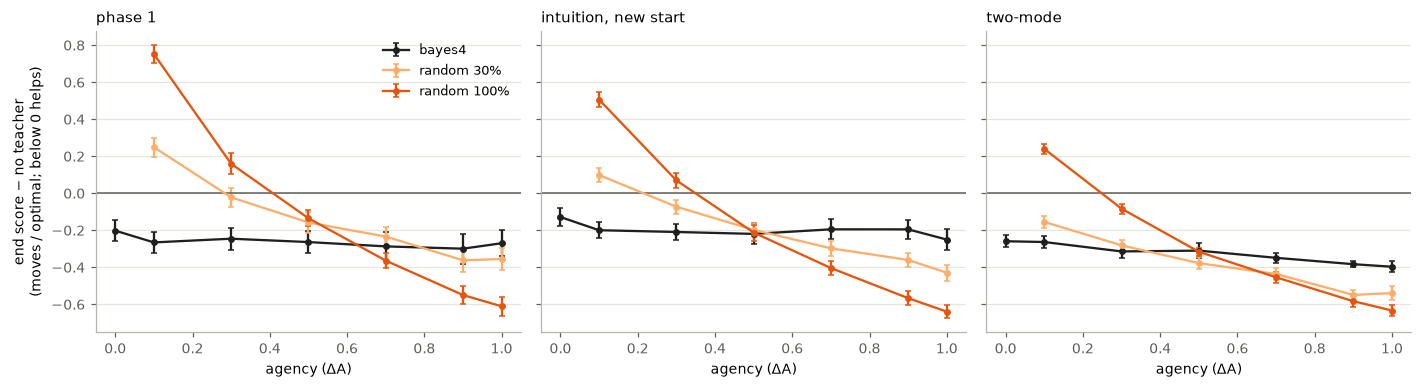

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (student, t) in zip(axes, tables.items()):
    for teacher, label in TEACHERS.items():
        d = t[t.teacher == teacher].sort_values("agency")
        ax.errorbar(d.agency, d.pooled, yerr=d["pooled se"], fmt="o-", ms=3.5, capsize=2, color=T_COLORS[teacher],
                    label=label)
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_title(student)
    ax.set_xlabel("agency (ΔA)")
    tidy(ax)
axes[0].set_ylabel("end score − no teacher\n(moves / optimal; below 0 helps)")
axes[0].legend()
plt.tight_layout()
plt.show()

side = None
for student, t in tables.items():
    t = t.assign(teacher=t.teacher.map(TEACHERS))
    t = t.set_index(["agency", "teacher"])[["pooled", "better"]].rename(
        columns={"pooled": (student, "− none"), "better": (student, "better")})
    side = t if side is None else side.join(t, how="outer")
side.columns = pd.MultiIndex.from_tuples(side.columns)
side.style.format("{:+.2f}", subset=[c for c in side.columns if c[1] == "− none"])

- **Both of phase 1's results hold for the two-mode student.**
  - bayes4 beats no teacher at every ΔA, by 0.26-0.40, for 23-24 of 24 students at each ΔA. Its gain grows with
    ΔA (−0.26 at ΔA 0 and 0.1, −0.40 at ΔA 1), where phase 1's stayed level at 0.20-0.30.
  - Showing every move goes from harmful at ΔA 0.1 (+0.24) to the best help at ΔA 1 (−0.63), and overtakes bayes4
    between ΔA 0.5 (−0.32 against −0.31, a tie) and 0.7 (−0.45 against −0.35), as in phase 1.
- **But showing moves stops hurting much sooner.** Showing every move costs the two-mode student +0.24 at ΔA 0.1,
  against +0.75 in phase 1. It already helps at ΔA 0.3 (−0.08, 15 of 24 students). Random 30% helps at every ΔA, even
  0.1 (−0.15), comes within 0.03 of bayes4 at ΔA 0.3 and beats it from 0.5 on (−0.38 against −0.31). In
  phase 1 random 30% hurt at 0.1 (+0.25) and only beat bayes4 from 0.9.
- **The intuition student on the new start lies between the two.** Showing every move costs it +0.51 at ΔA 0.1;
  random 30% hurts only at 0.1 (+0.10). bayes4 helps it a little less than in phase 1 (−0.13 to −0.25), for 17-20 of
  24 students. So the new start accounts for part of the shift and the two-mode play for the rest, in the same
  direction.
- **At ΔA 1 the three agree**: showing every move gives −0.61 to −0.64, random 30% −0.36 to −0.54.

## 2. The student no teacher meets

Each test of the no-teacher session (every 18 people's trials; 200 puzzles of 9-26 moves, played 3 times, untaught and
without giving up), averaged over the 8 students of each seed and the three seeds.

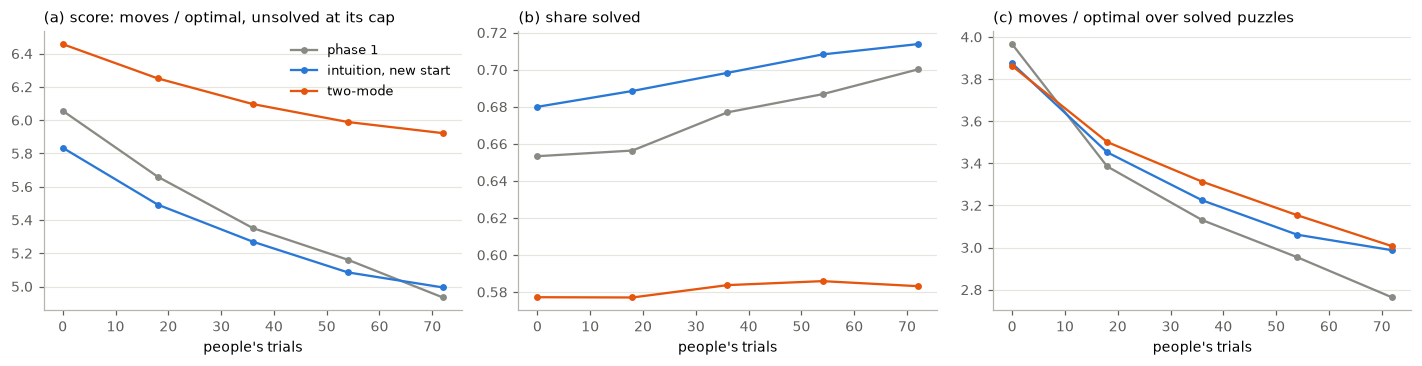

,score at start,score at end,gain,solved at start,solved at end
student,,,,,
phase 1,6.056,4.934,1.122,0.653,0.700
"intuition, new start",5.834,4.995,0.840,0.680,0.714
two-mode,6.457,5.922,0.535,0.577,0.583


In [3]:
curve = untaught.groupby(["student", "trial"])[["score", "solved", "moves / optimal (solved)"]].mean()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for student in STUDENTS:
    d = curve.loc[student]
    for ax, col in zip(axes, d.columns):
        ax.plot(d.index, d[col], "o-", ms=3.5, color=S_COLORS[student], label=student)
for ax, title in zip(axes, ["(a) score: moves / optimal, unsolved at its cap", "(b) share solved",
                            "(c) moves / optimal over solved puzzles"]):
    ax.set_title(title)
    ax.set_xlabel("people's trials")
    tidy(ax)
axes[0].legend()
plt.tight_layout()
plt.show()
ends = curve.unstack("trial")
pd.DataFrame({"score at start": ends[("score", 0)], "score at end": ends[("score", 72)],
              "gain": ends[("score", 0)] - ends[("score", 72)], "solved at start": ends[("solved", 0)],
              "solved at end": ends[("solved", 72)]}).loc[list(STUDENTS)].round(3)

- **The two-mode student starts worse and gains less on this score.** Its test score goes from 6.46 to 5.92,
  a gain of 0.54, against 5.83 → 5.00 (0.84) for the intuition student on the same start and 6.06 → 4.93 (1.12) in
  phase 1.
- **The difference is the solve rate.** The two-mode student solves 58% of the test puzzles at the start and 58% at
  the end. The intuition students go from 65-68% to 70-71%. On the puzzles it solves, the two-mode student gets about
  as much more efficient as the others (about 3.9 → 3.0 moves / optimal, against 3.9 → 2.8-3.0), so its gain comes
  from efficiency, not from solving more. The unsolved puzzles count at 10 × optimal and dominate the score.
- **Why it solves fewer** is section 4: none of its modes, but its soft memory, which lets it loop on long puzzles.
  These tests reach 26 moves and allow up to 10 × optimal, longer than most of people's puzzles. The tracking check
  (p2_summary, section 9) found the same: untaught, the two-mode student solves 25% of 19-26-move puzzles against the
  intuition student's 38%.

So the two-mode student leaves a teacher more room (its untaught end score is 5.92 against 4.93-5.00), and gains less on
this score.

## 3. The effects relative to where each student ends

Since the two-mode student ends worse untaught, each effect divided by that student's untaught end score (seeds
pooled): the share of the end score a teacher removes or adds.

In [4]:
rel = {}
for student, t in tables.items():
    rel[student] = (t.set_index(["agency", "teacher"]).pooled / none_end[student]).rename(index=TEACHERS, level=1)
rel = pd.DataFrame(rel)
print("untaught end score:", none_end.loc[list(STUDENTS)].round(2).to_dict())
rel.style.format("{:+.1%}")

untaught end score: {'phase 1': 4.93, 'intuition, new start': 4.99, 'two-mode': 5.92}


- **Relative to its baseline, bayes4 helps the two-mode student about as much as it helped phase 1's student**:
  4-7% of the end score against 4-6%. The intuition student on the new start gains less (3-5%). The larger absolute
  effect in section 1 is mostly the weaker baseline.
- **Showing every move at low ΔA still hurts the two-mode student far less**: +4% at ΔA 0.1, against +10% for the
  intuition student on the same start and +15% in phase 1. This difference isn't the baseline.
- **At ΔA 1, showing every move helps all three by 11-13%.**

**A reading, not tested here:** a shown move costs the student the learning it would have had from its own play.
With random 100% at ΔA 0.1 it learns from only a tenth of the session's moves. The two-mode student's own play teaches
it least (gain 0.54 against 0.84 and 1.12, section 2), so it has the least to lose. Shown moves also lead to solved
attempts, which are the only attempts it learns from, and it solves fewest on its own.

## 4. Why the two-mode student solves fewer

*(`experiments/solve_rate.py` → `models/summary/solve_rate/attempts.csv`)* Seed 0's test puzzles (200 of 9-26 moves;
untaught, no giving up, a cap of 10 × optimal) played by three kinds of network: the start (16 attempts per puzzle),
and the 8 end-of-session students of each no-teacher run (2 attempts each). Each network plays five ways:
- the two-mode student's play, as the tests play it;
- the same without AND-OR, or without flat planning;
- intuition with the soft memory;
- phase 1's play: intuition with its hard memory (never back to one of the last 10 boards if it can avoid it).

In [5]:
from IPython.display import display

PLAYS = ["two-mode", "no AND-OR", "no flat", "intuition, soft memory", "intuition, hard memory"]
NETS = ["start", "after two-mode session", "after intuition session"]
sr = pd.read_csv(os.path.join(p2.SUMMARY, "solve_rate", "attempts.csv"))
sr["length"] = pd.cut(sr.distance, [0, 11, 16, 21, 26], labels=["9-11", "14-16", "19-21", "24-26"])
sr["new boards"] = sr.boards / (sr.moves + 1)
solved = sr.pivot_table(index="network", columns="play", values="solved").loc[NETS, PLAYS]
by_length = sr.pivot_table(index=["network", "length"], columns="play", values="solved", observed=True).loc[NETS, PLAYS]
looping = sr[~sr.solved].pivot_table(index="network", columns="play", values="new boards").loc[NETS, PLAYS]
efficiency = sr[sr.solved].assign(r=lambda d: d.moves / d.distance).pivot_table(
    index="network", columns="play", values="r").loc[NETS, PLAYS]
# the session's gain in solve rate, paired by puzzle (an attempt's seed // 1000 is its puzzle)
start = sr[sr.network == "start"].groupby(["play", sr.seed // 1000]).solved.mean()
gain = {}
for net in NETS[1:]:
    end = sr[sr.network == net].groupby(["play", sr.seed // 1000]).solved.mean()
    d = (end - start).groupby("play")
    gain[net] = d.mean().round(3).astype(str) + " ± " + (d.std() / np.sqrt(d.size())).round(3).astype(str)
display(solved.style.format("{:.3f}").set_caption("share solved"))
display(by_length.style.format("{:.3f}").set_caption("share solved, by length"))
display(looping.style.format("{:.2f}").set_caption("unsolved attempts: share of moves that reach a new board"))
display(efficiency.style.format("{:.2f}").set_caption("solved attempts: moves / optimal"))
pd.DataFrame(gain).T[PLAYS].style.set_caption("solve rate after the session − at the start, paired by puzzle (± SE)")

play,two-mode,no AND-OR,no flat,"intuition, soft memory","intuition, hard memory"
network,,,,,
start,0.567,0.570,0.543,0.540,0.668
after two-mode session,0.572,0.562,0.561,0.543,0.672
after intuition session,0.577,0.574,0.556,0.556,0.682


play,two-mode,no AND-OR,no flat,"intuition, soft memory","intuition, hard memory"
network,,,,,
start,0.46,0.48,0.47,0.49,0.70
after two-mode session,0.28,0.28,0.28,0.29,0.49
after intuition session,0.30,0.29,0.30,0.30,0.49


play,two-mode,no AND-OR,no flat,"intuition, soft memory","intuition, hard memory"
network,,,,,
start,3.93,4.01,3.88,3.94,3.89
after two-mode session,3.00,3.01,2.98,2.96,2.89
after intuition session,2.99,3.04,2.99,3.03,2.93


play,two-mode,no AND-OR,no flat,"intuition, soft memory","intuition, hard memory"
after two-mode session,0.005 ± 0.017,-0.008 ± 0.017,0.018 ± 0.016,0.004 ± 0.017,0.003 ± 0.016
after intuition session,0.01 ± 0.017,0.004 ± 0.018,0.013 ± 0.016,0.016 ± 0.017,0.014 ± 0.014


- **Memory, not planning, sets the level.** With the same network, phase 1's hard memory solves about 10 points
  more than the soft memory (0.67-0.68 against 0.54-0.58), and 15-17 points more on 19-26-move puzzles. AND-OR and
  flat planning together add only 2-3 points over intuition with the same soft memory. On the puzzles they solve, all
  five plays are equally efficient.
- **What fails is looping.** In unsolved attempts under the soft memory, 46-49% of moves reach a new board at the start
  and 28-30% after the session: about 60 distinct boards in 200 moves or more. Under the hard memory, 70% and 49%. As
  the policy sharpens with learning, it steers back to the same boards more often.
- **The network learns as well either way.** Played the same way, the networks trained in the two-mode session and in
  the intuition session solve within 1-2 points of each other.
- **The flat solve rate isn't the two-mode student's alone.** Paired by puzzle, every play's solve rate changes by only
  −0.01 to +0.02 over the session (SE about 0.016), the hard memory included. Learning trades puzzles: 14-16-move
  puzzles drop 5-7 points and 24-26-move ones rise 7-8. The intuition run at seed 0 gained as little in its own tests
  (+0.016); its larger pooled gain (section 2) comes from seeds 1 and 2.

**Is the soft memory too weak?** It was fitted (`experiments/fit_memory.py`) to people's returns to earlier boards on
solved attempts of 1.5-3 × optimal only, which can't see an attempt that fails. Below, all of people's attempts on
their 70 layouts, by length, against the fit's simulations (that fit's start network by intuition; cap 10 × optimal,
no giving up): the share of moves that return to an earlier board.

In [6]:
import fit_memory as fm

mv = fm._people()
att = mv.groupby(["who", "instance", "attempt"]).agg(n=("move", "size"), L=("optimal length", "first"),
                                                       solved=("solved", "first"),
                                                       returns=("board age", lambda a: a.notna().sum()))
att["ratio"] = att.n / att.L
sims = pd.read_csv(os.path.join(p2.SUMMARY, "memory_fit.csv"))
sims["returns"] = sims.ages.fillna("").map(lambda s: len(s.split()))
sims["ratio"] = sims.moves / sims.optimal
MEMORIES = {"beta 2, half-life 1": "soft (β 2, half-life 1)", "beta 2, half-life 8": "β 2, half-life 8",
            "hard, last 10 boards": "hard, last 10 boards", "no memory": "no memory"}
rows = []
for lo, hi in [(1.5, 3), (3, 5), (5, 8), (8, 10.01)]:
    p = att[att.ratio.between(lo, hi, inclusive="left")]
    row = {"attempt (× optimal)": f"{lo:g}-{min(hi, 10):g}", "people": p.returns.sum() / p.n.sum(),
           "people's attempts": len(p)}
    for key, label in MEMORIES.items():
        q = sims[(sims.condition == key) & sims.ratio.between(lo, hi, inclusive="left")]
        row[label] = q.returns.sum() / q.moves.sum()
    rows.append(row)
print(f"people solve {att.solved.mean():.0%} of their attempts (giving up counted as unsolved)")
pd.DataFrame(rows).set_index("attempt (× optimal)").style.format("{:.3f}").format("{:d}", subset=["people's attempts"])

people solve 70% of their attempts (giving up counted as unsolved)


,people,people's attempts,"soft (β 2, half-life 1)","β 2, half-life 8","hard, last 10 boards",no memory
attempt (× optimal),,,,,,
1.5-3,0.112,913,0.086,0.035,0.001,0.110
3-5,0.172,295,0.145,0.063,0.030,0.190
5-8,0.236,91,0.217,0.102,0.060,0.246
8-10,0.298,24,0.315,0.195,0.151,0.373


- **People loop as much as the soft memory does, even in their long attempts.** 17% of their moves return to an
  earlier board at 3-5 × optimal and 24% at 5-8 × (the soft memory: 15% and 22%; the hard memory: 3% and 6%). In their
  longest attempts, people revisit about as much as a student with no memory.
- **So the soft memory stays.** A stronger memory would solve more by forcing the student onto new boards, which
  people don't do. What people have and the student lacks is a way out from where they are: the mid-puzzle skill gap
  (`MODEL.md`, premise 12: people make 48-59% optimal moves 7-9 from the goal, the student 33-36%). On these tests
  it shows as looping, most on the 19-26-move puzzles, which are longer than most of people's.
- **Caveats.** People's restarts take them back to the start board and may count as returns. Only 24 of people's
  attempts run past 8 × optimal. People give up, and solve 70% of attempts counting that, against the student's
  58% without giving up.

## 5. bayes4's θ for the two-mode student

bayes4's θ (0.45) and its model of the student come from phase 1 and weren't refitted for this student. Phase 1's
check repeated (`replication_queue.py --theta`): bayes4 at θ 0.25, 0.75 and 0.9 beside 0.45, at ΔA 0, 0.3 and 1, seed
0 (8 students), each against no teacher. `replication_theta.csv`, beside phase 1's `bayes4_theta.csv`.

In [7]:
th = pd.concat({"phase 1": pd.read_csv(os.path.join(p2.SUMMARY, "bayes4_theta.csv")),
                "two-mode": pd.read_csv(os.path.join(p2.SUMMARY, "replication_theta.csv"))}, names=["student"])
th = th.reset_index("student").pivot_table(index=["agency", "theta"], columns="student", values=["vs none", "shown"])
th.columns = [f"{s}: {m}" for m, s in th.columns]
th.index = pd.MultiIndex.from_tuples([(f"{a:g}", f"{t:g}") for a, t in th.index], names=["agency", "theta"])
# random 30% at seed 0, for the same spend
r30 = {s: tables[s].set_index(["agency", "teacher"])["seed 0"].xs("random:0.3", level="teacher")
       for s in ("phase 1", "two-mode")}
print("random 30% at seed 0 (vs none):", {s: r.loc[[0.3, 1.0]].round(3).to_dict() for s, r in r30.items()})
cols = ["phase 1: vs none", "two-mode: vs none", "phase 1: shown", "two-mode: shown"]
th[cols].style.format("{:+.3f}", subset=cols[:2]).format("{:.1%}", subset=cols[2:])

random 30% at seed 0 (vs none): {'phase 1': {0.3: -0.189, 1.0: -0.556}, 'two-mode': {0.3: -0.247, 1.0: -0.448}}


- **The same shape as phase 1, so θ 0.45 stays.**
  - θ 0.25 and 0.45 do alike at every ΔA (−0.19 to −0.31), showing 5-7% of moves.
  - θ 0.75 shows 12-15%. It is worse at ΔA 0 (−0.03), as good at 0.3, and better at 1 (−0.45 against −0.31).
  - θ 0.9 shows 30-34%. It hurts at ΔA 0 (+0.37), does nothing at 0.3, and does best at 1 (−0.48).

  Phase 1 found the same. Recalibrating θ doesn't make the dilemma steeper again.
- **At the same spend, random does better than bayes4 at middling ΔA.** bayes4 at θ 0.9 shows about as many moves as
  random 30%, but at ΔA 0.3 it ends no better than no teacher (+0.01), while random 30% helps (−0.25; seed 0). At ΔA 1
  they are about even (−0.48 against −0.45). Phase 1 shows the same at ΔA 0.3, less strongly (−0.12 against −0.19).
  **A reading:** bayes4 shows runs of moves on the puzzles it expects the student to fail, so whole stretches of those
  puzzles teach only at ΔA, while random spreads the same spend thinly.

## 6. What each teacher leaves the student to learn from

Why bayes4's lead over random 30% shrinks from phase 1 to the two-mode student (section 1). The student learns only
from puzzles it solves (full hindsight labels through every board of the attempt), and an example on a board where a
move was shown counts ΔA. Per session, pooled over the 24 students: the share of puzzles solved, the learning examples,
and those examples weighted (each solved attempt's examples discounted by its share of shown moves × (1 − ΔA), an
approximation of the weights training used).

In [8]:
rows = []
for student, seeds in STUDENTS.items():
    for seed, pattern in seeds.items():
        for a, teacher in [(1.0, "none")] + [(a, t) for a in (0.1, 0.3, 1.0) for t in TEACHERS]:
            e = an.entry(pattern.format(f"{a:g}"), teacher)
            for s, record in e["sessions"].items():
                df = pd.DataFrame(record)
                won = df[df.solved]
                lost = (won.taught / won.moves).fillna(0) * (1 - a) if teacher != "none" else 0
                rows.append({"student": student, "teacher": TEACHERS.get(teacher, "none"),
                             "agency": "-" if teacher == "none" else f"{a:g}", "solved": df.solved.mean(),
                             "solved, 19-26 moves": df[df.distance >= 19].solved.mean(),
                             "examples": df.examples.sum(), "weighted": (won.examples * (1 - lost)).sum()})
data = pd.DataFrame(rows).groupby(["student", "agency", "teacher"], sort=False).mean()
base = data.xs("none", level="teacher")["weighted"].droplevel("agency")
data["weighted / no teacher"] = data.weighted / data.index.get_level_values("student").map(base)
data.loc[list(STUDENTS)].style.format("{:.2f}", subset=["solved", "solved, 19-26 moves", "weighted / no teacher"]) \
    .format("{:,.0f}", subset=["examples", "weighted"])

- **The two-mode student has little to learn from on its own.** It solves 53% of its session's puzzles (27% of
  those of 19-26 moves) against the intuition students' 63-64% (42%), and learns from about a third fewer examples.
- **So random 30% gives it more to learn from, not less.** Shown moves turn its loops into solved puzzles. Even with
  the shown boards discounted, at ΔA 0.1 it learns from 1.22 × what it learns alone; the intuition students from
  0.87-0.94 ×. That's why random 30% helps the two-mode student at ΔA 0.1 and hurts the others.
- **bayes4 roughly doubles what every student learns from** (1.7-2.0 ×), so its lead over random 30% at ΔA 0.1 falls
  from about 1.9 × in learning data for the intuition students to 1.6 × for the two-mode student.

This matches the scores but doesn't establish the cause; "weighted" is an approximation.

## 7. Planning more when stuck

Can the two-mode student plan its way out of a loop? *(`experiments/stuck_planning.py` →
`models/summary/stuck_planning/attempts.csv`; `solve_two_mode(stuck=...)`, off by default.)* On a board the attempt has
been on before, the modes are drawn with higher planning odds. Seed 0's test puzzles as in section 4, the start (8
attempts per puzzle) and the two-mode session's 8 students (1 each).

In [9]:
stuck = pd.read_csv(os.path.join(p2.SUMMARY, "stuck_planning", "attempts.csv"))
stuck["new boards"] = stuck.boards / (stuck.moves + 1)
rows = []
for (net, play), g in stuck.groupby(["network", "play"], sort=False):
    rows.append({"network": net, "on a returned board": play, "solved": g.solved.mean(),
                 "solved, 19-26 moves": g[g.distance >= 19].solved.mean(),
                 "AND-OR share": g["moves and-or"].sum() / g.moves.sum(), "flat share": g["moves flat"].sum() / g.moves.sum(),
                 "unsolved: new boards": g[~g.solved]["new boards"].mean()})
pd.DataFrame(rows).set_index(["network", "on a returned board"]).style.format("{:.2f}")

- **Planning more doesn't get it out.** Even with AND-OR on every move from a returned board, 60-72% of all moves,
  it solves no more (0.55-0.56 against 0.56-0.58). AND-OR ignores the memory and is ordered by the same policy.
- **Flat planning on every such move makes it worse** (0.47-0.51): it judges by a value network that keeps favouring
  the boards it knows, and the student loops more.
- **People don't plan much more when stuck either.** From a board they return to, 13.6% of their moves are slow
  (over 2.5 × their median time; the moves the mode mixture gives to deliberation) against 11.9% from a fresh board,
  for 29 of 42 people. That is about 15% more planning, far less than any row above.

Every mode draws on the same knowledge, so changing the odds between them can't add what the network lacks.

## 8. How people and the student loop on people's own layouts

So far the difference between the two students is their memory, not their modes (section 4). *(`experiments/loops.py` →
`models/summary/solve_rate/loops.csv`.)* Every attempt of people's on their 70 layouts (6-15 moves), against the start
network playing each layout 10 times as the two-mode student, by intuition with the soft memory, and with phase 1's
hard memory (cap 10 × optimal, no giving up). People's boards are identified by chaining each move's board age.
- **returns / move**: moves to a board the attempt has been on before;
- **third+ visits**: of the returns, those to a board already visited twice or more;
- **same exit**: after a return, leaving the board the way the attempt left it last time;
- **max visits**: the most visits to one board.

In [10]:
lp = pd.read_csv(os.path.join(p2.SUMMARY, "solve_rate", "loops.csv"))
lp["length"] = pd.cut(lp.moves / lp.optimal, [0, 1.5, 3, 5, 8, 10.01], labels=["<1.5", "1.5-3", "3-5", "5-8", "8-10"])
WHO = ["people", "soft (two-mode)", "soft (intuition)", "hard (intuition)"]


def loop_table(g):
    return pd.DataFrame({"attempts": g.size(), "returns / move": g.returns.sum() / g.moves.sum(),
                         "third+ visits": g["third+"].sum() / g.returns.sum(),
                         "same exit": g["same exit"].sum() / g.exits.sum(), "max visits": g["max visits"].mean(),
                         "solved": g.solved.mean()})


display(loop_table(lp.groupby("who")).loc[WHO].style.format("{:.3f}").format("{:d}", subset=["attempts"])
        .set_caption("all attempts"))
by = loop_table(lp.groupby(["length", "who"], observed=True))
by = by.reindex([(l, w) for l in by.index.levels[0] for w in WHO]).dropna(how="all")
by.style.format("{:.3f}").format("{:.0f}", subset=["attempts"]).set_caption("by attempt length (× optimal)")

,attempts,returns / move,third+ visits,same exit,max visits,solved
who,,,,,,
people,2804,0.145,0.262,0.160,1.826,0.703
soft (two-mode),700,0.357,0.503,0.198,4.666,0.673
soft (intuition),700,0.325,0.465,0.181,4.530,0.640
hard (intuition),700,0.134,0.277,0.177,1.996,0.697


- **Up to 8 × optimal, the soft-memory student loops as people do**: as often (e.g. 0.17-0.19 returns per move at
  3-5 × optimal; people 0.18), back to the same boards as often (third+ visits 20-27%; people 23%), and leaving them
  the same way as often (15-20%; people 11-20%). People don't escape by taking another exit. The hard memory is unlike
  people at every length (0.03 returns per move at 3-5 ×).
- **On these layouts the soft memory costs little**: the two-mode student solves 67%, the hard memory 70%, people
  70% (people counting giving up as unsolved; the student never gives up here).
- **The students part from people past 8 × optimal**, which people almost never reach (24 attempts): they solve or
  give up first. The student plays on to the cap, and a third of its attempts end there, with boards visited 7-9 times
  against people's 5.
- **The teaching tests are mostly there.** Their puzzles are 9-26 moves, played to 10 × optimal without giving up.
  Two of their four length bins (19-21, 24-26) are longer than any puzzle people played. That is where the soft memory
  costs 15-17 points (section 4) and the two students differ most.

So hard against soft memory decides the outcome only outside people's data, where neither memory was fitted. Within
people's data the soft memory is right and the hard memory is not. Choosing the intuition student for its solve rate
would rely on a rule people don't follow.

## 9. The replication within people's lengths

The three sweeps scored again on the end test's puzzles of 9-11 and 14-16 moves only (people played 6-15), from the
saved tests (`replication_analysis.py` → `models/summary/replication_within_people.csv`). Each teacher against no
teacher, pooled over seeds 0-2, ± 1 SE across the 24 students.

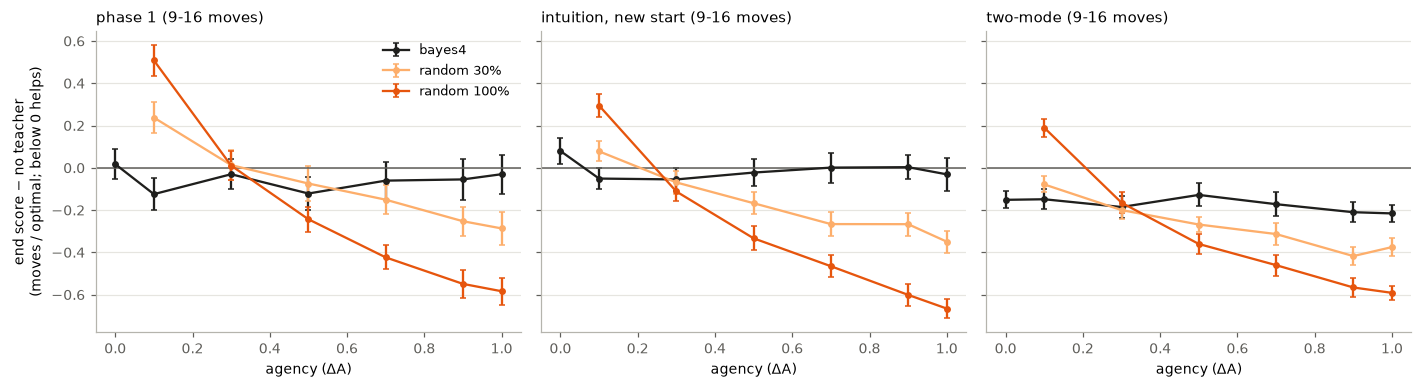

untaught end score on these puzzles: {'intuition, new start': 3.3, 'phase 1': 3.28, 'two-mode': 3.88}


student                          phase 1  intuition, new start  \
agency teacher                                                   
0.0    bayes4       +0.02 ± 0.07 (12/24)  +0.08 ± 0.06 (10/24)   
0.1    bayes4       -0.12 ± 0.08 (16/24)  -0.05 ± 0.05 (14/24)   
       random 100%   +0.51 ± 0.07 (1/24)   +0.29 ± 0.05 (4/24)   
       random 30%    +0.24 ± 0.07 (6/24)  +0.08 ± 0.05 (11/24)   
0.3    bayes4       -0.03 ± 0.07 (14/24)  -0.05 ± 0.05 (15/24)   
       random 100%  +0.01 ± 0.07 (12/24)  -0.11 ± 0.05 (18/24)   
       random 30%   +0.01 ± 0.07 (14/24)  -0.07 ± 0.05 (14/24)   
0.5    bayes4       -0.12 ± 0.08 (16/24)  -0.02 ± 0.06 (13/24)   
       random 100%  -0.24 ± 0.06 (18/24)  -0.33 ± 0.06 (20/24)   
       random 30%   -0.07 ± 0.08 (13/24)  -0.17 ± 0.05 (18/24)   
0.7    bayes4       -0.06 ± 0.09 (13/24)  +0.00 ± 0.07 (13/24)   
       random 100%  -0.42 ± 0.06 (24/24)  -0.47 ± 0.05 (23/24)   
       random 30%   -0.15 ± 0.07 (14/24)  -0.27 ± 0.06 (18/24)   
0.9    bayes4       -0.05 ± 0.10 (14/24)  +0.00 ± 0.06 (13/24)   
       random 100%  -0.55 ± 0.07 (23/24)  -0.60 ± 0.05 (24/24)   
       random 30%   -0.25 ± 0.07 (17/24)  -0.27 ± 0.05 (21/24)   
1.0    bayes4       -0.03 ± 0.09 (13/24)  -0.03 ± 0.08 (15/24)   
       random 100%  -0.58 ± 0.06 (24/24)  -0.67 ± 0.05 (24/24)   
       random 30%   -0.29 ± 0.08 (18/24)  -0.35 ± 0.05 (20/24)   

student                         two-mode  
agency teacher                            
0.0    bayes4       -0.15 ± 0.04 (18/24)  
0.1    bayes4       -0.15 ± 0.05 (19/24)  
       random 100%   +0.19 ± 0.04 (6/24)  
       random 30%   -0.08 ± 0.04 (15/24)  
0.3    bayes4       -0.19 ± 0.05 (17/24)  
       random 100%  -0.16 ± 0.05 (17/24)  
       random 30%   -0.20 ± 0.04 (20/24)  
0.5    bayes4       -0.13 ± 0.05 (19/24)  
       random 100%  -0.36 ± 0.05 (23/24)  
       random 30%   -0.27 ± 0.04 (22/24)  
0.7    bayes4       -0.17 ± 0.06 (15/24)  
       random 100%  -0.46 ± 0.05 (23/24)  
       random 30%   -0.31 ± 0.05 (21/24)  
0.9    bayes4       -0.21 ± 0.05 (19/24)  
       random 100%  -0.57 ± 0.04 (24/24)  
       random 30%   -0.42 ± 0.04 (23/24)  
1.0    bayes4       -0.22 ± 0.04 (20/24)  
       random 100%  -0.59 ± 0.03 (24/24)  
       random 30%   -0.37 ± 0.04 (23/24)

In [11]:
within = pd.read_csv(os.path.join(p2.SUMMARY, "replication_within_people.csv"))
within["student"] = within.student.map({"phase 1": "phase 1", "intuition": "intuition, new start",
                                        "twomode": "two-mode"})
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, student in zip(axes, STUDENTS):
    t = within[within.student == student]
    for teacher, label in TEACHERS.items():
        d = t[t.teacher == teacher].sort_values("agency")
        ax.errorbar(d.agency, d.pooled, yerr=d["pooled se"], fmt="o-", ms=3.5, capsize=2, color=T_COLORS[teacher],
                    label=label)
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_title(f"{student} (9-16 moves)")
    ax.set_xlabel("agency (ΔA)")
    tidy(ax)
axes[0].set_ylabel("end score − no teacher\n(moves / optimal; below 0 helps)")
axes[0].legend()
plt.tight_layout()
plt.show()
within["cell"] = (within.pooled.map("{:+.2f}".format) + " ± " + within["pooled se"].map("{:.2f}".format)
                  + " (" + within.better + ")")
print("untaught end score on these puzzles:", within.groupby("student")["none end"].first().round(2).to_dict())
within.assign(teacher=within.teacher.map(TEACHERS)).pivot_table(
    index=["agency", "teacher"], columns="student", values="cell", aggfunc="first")[list(STUDENTS)]

- **Showing every move is robust.** For all three students it hurts at ΔA 0.1 (+0.19 to +0.51), crosses zero by
  ΔA 0.3-0.5, and is the best help at ΔA 1 (−0.58 to −0.67). Random 30% beats bayes4 from ΔA 0.5 (phase 1's student: 0.7).
- **bayes4's help to the intuition students isn't.** Within people's lengths its effect on them is −0.12 to +0.08,
  within about 1.5 SE of zero at every ΔA, with only 10-16 of 24 students doing better than with no teacher (phase 1's
  student and phase 1's play on the new start alike). Phase 1's "bayes4 helps at every ΔA" (−0.20 to −0.30) came from
  the 19-26-move puzzles, where the hard memory's behaviour isn't checked against people.
- **bayes4 still helps the two-mode student here**: −0.13 to −0.22 at every ΔA, for 15-20 of 24 students. It loops
  on these puzzles too, and bayes4 breaks the loops.
- **The untaught two-mode student is still weaker on these puzzles** (end score 3.88 against 3.28-3.30; it solves
  about 70% of the 14-16-move ones against 81%). They are pool puzzles people didn't play, so which student is closer
  to people on them is unknown; on people's own layouts the two are close (section 8).

## 10. What this means

- **Showing moves follows ΔA for every student and at every length**: harmful at low ΔA, the best help at ΔA 1, with
  random 30% overtaking bayes4 along the way. This part of phase 1 is robust.
- **bayes4 helping at every ΔA isn't.** For phase 1's student it holds only on puzzles longer than people played
  (section 9). On people's lengths its effect is indistinguishable from none. For the two-mode student it holds on
  both, because bayes4 breaks loops the student can't get out of.
- **Where the balance tips depends on the student.** The two-mode student learns from fewer solved puzzles, so shown
  moves cost it less (section 6). It crosses from harm to help between ΔA 0.1 and 0.3, not 0.3 and 0.5.
- **bayes4's θ isn't why the dilemma is flatter** (section 5): rechecked, 0.45 is still as good as any at low ΔA.
- **The crux is memory, not modes** (sections 4, 7, 8). The soft memory loops as people do on their layouts; the hard
  memory doesn't. They part only past 8 × optimal and on puzzles longer than people's, where neither is fitted,
  and that is where both the solve-rate gap and phase 1's bayes4 effect come from. Planning more when stuck doesn't
  help the student out; what it lacks is the mid-puzzle knowledge people use to find a way out.
- **The protocol extends past the data.** Half the tests' length bins (19-26 moves) and every attempt past 8 ×
  optimal are where no human data constrains the student. Results that depend on them should be read as
  extrapolation.

## 11. Salience: coming back to the same boards

Two ideas for the loops of sections 4-9, tested in order: a memory that notices repeated returns (sections 11, 13), and
a teacher that notices loops (sections 12, 13). Each was checked against people or in a replay before any teaching
run, and the teaching comparisons were fixed before the runs (`experiments/loops_queue.py`).

**Salience** (`solve_two_mode(salience=(λ, half-life))`): each return to a board after the first adds λ to the
board's soft-memory penalty, summed over returns. The soft memory as it was (β 2, half-life 1) let the student keep
coming back to the same boards in long attempts (past 8 × optimal, 55% of its returns were to a board visited twice
already; people 37%; section 8). λ 0.5, never fading, fits people's long attempts, keeps the soft memory's fit
elsewhere and the session's learning, and closes about half the solve-rate gap to the hard memory on the tests. The
**salient student** of sections 12-13 is the soft memory as it was plus that salience.

The fit, its checks, and the later test of whether salience's parameter is needed (after which the student's memory
became soft β 1, half-life 4, plus salience λ 0.5) are in **`p2.7_feature_tests.ipynb`, sections 1-2**.

## 12. A teacher that notices loops

bayes4 judges how hard a puzzle is for the student from whether its moves bring the puzzle closer. Many moves in a
loop do, such as undoing a step away, so bayes4 can go on believing the student is fine while it goes round in
circles. **Loop-aware bayes4** (`Bayesian4(loops=1)`, spec `bayes4:0.45,loops=1`) counts a move of the student's own
back onto a board it has been on in this attempt as a misstep in its belief about the puzzle. The skill it carries
across puzzles counts the move as before.

**A replay without learning** (`experiments/bayes4_loops.py` → `models/summary/bayes4_loops/attempts.csv`): the start
network plays every third puzzle of seed 0's session (240 puzzles of 9-26 moves, in order) with the session's giving
up and cap, 3 sequences per student and teacher. First shown: the median of the first shown move's position,
÷ optimal; returns before: the student's returns to earlier boards before it.

In [12]:
rp = pd.read_csv(os.path.join(p2.SUMMARY, "bayes4_loops", "attempts.csv"))
g = rp.groupby(["student", "teacher"])
pd.DataFrame({"solved": g.solved.mean(), "gave up": g["gave up"].mean(), "shown": g.shown.sum() / g.moves.sum(),
              "first shown ÷ optimal": g.apply(lambda d: (d["first shown"] / d.distance).median()),
              "returns before": g.apply(lambda d: d.loc[d["first shown"].notna(), "returns before"].mean())}) \
    .style.format("{:.3f}")

- **It steps in sooner**: the first shown move comes at about 2 × optimal instead of 3.5-3.7 × for the two-mode
  students, after about 13 returns instead of 27-30.
- **More of the puzzles get solved**: 0.78 → 0.86 for the soft-memory student, 0.79 → 0.84 for the salient one,
  0.80 → 0.83 for phase 1's intuition student, which loops least.
- **It shows more**: 9.6% of the salient student's moves against bayes4's 6.4%. Random 10% is the teacher at the
  same spend in section 13.

## 13. The teaching runs

`experiments/loops_queue.py` (queues `loops_a`, `loops_b`): the salient student (spec.STUDENT with salience λ 0.5,
never fading) at ΔA 0.1, 0.5 and 1, seeds 0-2, with no teacher (at ΔA 1 only), bayes4, loop-aware bayes4 and random
10%; runs `salient_m10[_s<seed>]_agency<a>`. Loop-aware bayes4 was added to the soft-memory runs of the replication
(`twomode_m10*`). The comparisons, fixed before the runs, each paired by student (24) at each ΔA:
1. bayes4 against no teacher, on the salient student;
2. loop-aware bayes4 against bayes4, on the salient and on the soft student, and the difference between the two (the
   memory × teacher interaction; different students, so unpaired);
3. loop-aware bayes4 against random 10%, on the salient student.

Primary: the end score on the end test's 9-16-move puzzles (people's lengths, section 9); secondary: all of them.
`experiments/loops_analysis.py` → `models/summary/loops_stage1.csv` and `loops_stage1_ends.csv`.

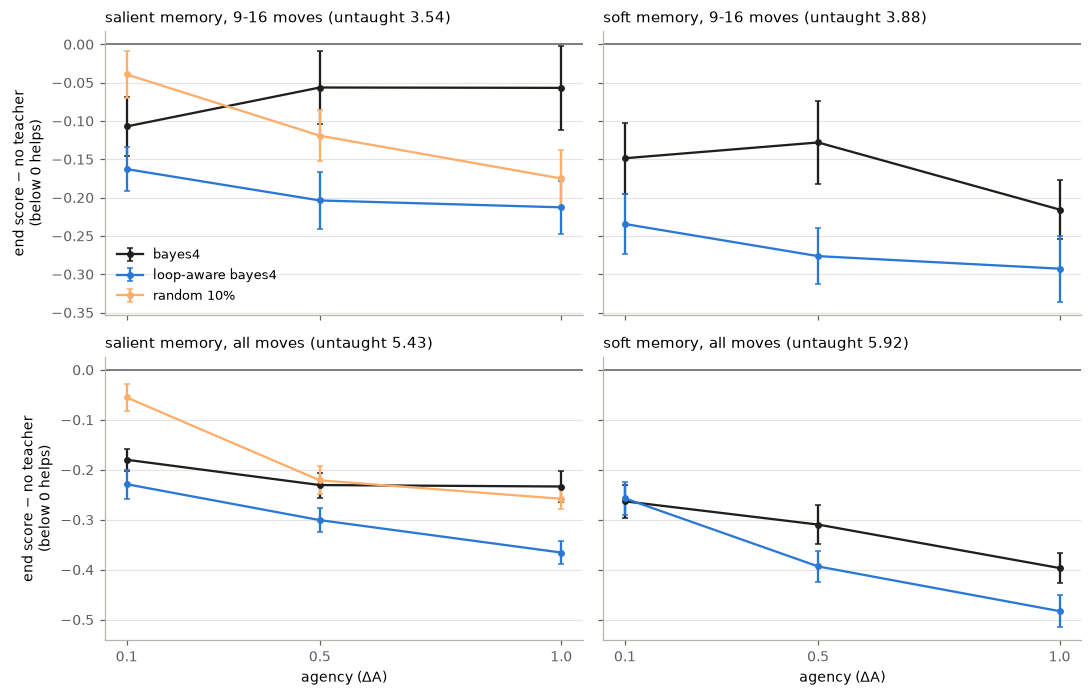

agency                                                               ΔA 0.1  \
scope comparison                      student                                 
9-16  1. bayes4 - none                salient  -0.11 ± 0.04 (z -2.8, 18/24)   
      2. interaction (salient - soft) both             +0.03 ± 0.06 (z 0.5)   
      2. loops - bayes4               salient  -0.06 ± 0.04 (z -1.4, 16/24)   
                                      soft     -0.09 ± 0.04 (z -2.1, 17/24)   
      3. loops - random 10%           salient  -0.12 ± 0.04 (z -3.4, 16/24)   
all   1. bayes4 - none                salient  -0.18 ± 0.02 (z -8.3, 24/24)   
      2. interaction (salient - soft) both            -0.05 ± 0.04 (z -1.2)   
      2. loops - bayes4               salient  -0.05 ± 0.03 (z -1.5, 17/24)   
                                      soft      +0.01 ± 0.03 (z 0.2, 11/24)   
      3. loops - random 10%           salient  -0.17 ± 0.03 (z -5.1, 22/24)   

agency                                                               ΔA 0.5  \
scope comparison                      student                                 
9-16  1. bayes4 - none                salient  -0.06 ± 0.05 (z -1.2, 15/24)   
      2. interaction (salient - soft) both             +0.00 ± 0.06 (z 0.0)   
      2. loops - bayes4               salient  -0.15 ± 0.05 (z -3.0, 17/24)   
                                      soft     -0.15 ± 0.04 (z -3.7, 19/24)   
      3. loops - random 10%           salient  -0.08 ± 0.04 (z -2.1, 15/24)   
all   1. bayes4 - none                salient  -0.23 ± 0.03 (z -9.2, 24/24)   
      2. interaction (salient - soft) both             +0.01 ± 0.05 (z 0.3)   
      2. loops - bayes4               salient  -0.07 ± 0.03 (z -2.3, 15/24)   
                                      soft     -0.08 ± 0.04 (z -2.3, 17/24)   
      3. loops - random 10%           salient  -0.08 ± 0.03 (z -2.5, 18/24)   

agency                                                                 ΔA 1  
scope comparison                      student                                
9-16  1. bayes4 - none                salient  -0.06 ± 0.05 (z -1.0, 12/24)  
      2. interaction (salient - soft) both            -0.08 ± 0.06 (z -1.4)  
      2. loops - bayes4               salient  -0.16 ± 0.04 (z -3.6, 15/24)  
                                      soft     -0.08 ± 0.03 (z -2.3, 16/24)  
      3. loops - random 10%           salient  -0.04 ± 0.03 (z -1.1, 13/24)  
all   1. bayes4 - none                salient  -0.23 ± 0.03 (z -7.5, 21/24)  
      2. interaction (salient - soft) both            -0.05 ± 0.05 (z -0.9)  
      2. loops - bayes4               salient  -0.13 ± 0.04 (z -3.4, 19/24)  
                                      soft     -0.09 ± 0.04 (z -2.4, 16/24)  
      3. loops - random 10%           salient  -0.11 ± 0.03 (z -4.2, 18/24)

In [13]:
import loops_analysis as la

stage1 = pd.read_csv(os.path.join(p2.SUMMARY, "loops_stage1.csv"))
ends1 = pd.read_csv(os.path.join(p2.SUMMARY, "loops_stage1_ends.csv"))
VS_NONE = {"bayes4": ("bayes4", INK, {"salient": "1. bayes4 - none", "soft": "(bayes4 - none)"}),
           "loops": ("loop-aware bayes4", "#2a78d6", {"salient": "(loops - none)", "soft": "(loops - none)"}),
           "random": ("random 10%", "#fdae6b", {"salient": "(random 10% - none)"})}
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), sharey="row", sharex=True)
for i, scope in enumerate(["9-16", "all"]):
    for ax, student in zip(axes[i], ["salient", "soft"]):
        none = ends1.query("scope == @scope and student == @student and teacher == 'none'").end.iloc[0]
        for label, color, names in VS_NONE.values():
            if student not in names:
                continue
            d = stage1[(stage1.scope == scope) & (stage1.student == student)
                       & (stage1.comparison == names[student])].sort_values("agency")
            ax.errorbar(d.agency, d["diff"], yerr=d.se, fmt="o-", ms=3.5, capsize=2, color=color, label=label)
        ax.axhline(0, color=MUTED, lw=1)
        ax.set_title(f"{student} memory, {scope} moves (untaught {none:.2f})")
        tidy(ax)
    axes[i][0].set_ylabel("end score − no teacher\n(below 0 helps)")
for ax in axes[1]:
    ax.set_xlabel("agency (ΔA)")
    ax.set_xticks(la.AGENCIES)
axes[0][0].legend()
plt.tight_layout()
plt.show()

PRIMARY = ["1. bayes4 - none", "2. loops - bayes4", "2. interaction (salient - soft)", "3. loops - random 10%"]
st1 = stage1[stage1.comparison.isin(PRIMARY)].copy()
st1["cell"] = (st1["diff"].map("{:+.2f}".format) + " ± " + st1.se.map("{:.2f}".format) + " (z "
               + st1.z.map("{:.1f}".format) + st1.better.map(lambda b: f", {b}" if isinstance(b, str) else "") + ")")
st1.pivot_table(index=["scope", "comparison", "student"], columns="agency", values="cell", aggfunc="first") \
    .reindex(["9-16", "all"], level=0).rename(columns="ΔA {:g}".format)

In [14]:
shown = ends1[(ends1.scope == "9-16") & (ends1.teacher != "none")].pivot_table(
    index=["student", "teacher"], columns="agency", values="shown").rename(columns="ΔA {:g}".format)
shown.style.format("{:.3f}").set_caption("share of the session's moves shown")

In the panels, bayes4 on the soft student is the replication's (section 9); the salient student's own no-teacher
run is its baseline. In the table a negative difference favours the first teacher named; (k/24) counts the students
it favours.

- **1. bayes4 helps the salient student less on people's lengths**: −0.11 at ΔA 0.1 (z −2.8), −0.06 at 0.5 and 1
  (z −1.0 to −1.2), against −0.13 to −0.22 for the soft student. The salient student loops less on its own (untaught
  3.54 against 3.88), so there is less for bayes4 to break. On all the tests bayes4 still helps it at every ΔA
  (−0.18 to −0.23, 21-24 of 24).
- **2. Loop-aware bayes4 beats bayes4 on both memories**: on the salient student by −0.06, −0.15 and −0.16 at ΔA 0.1,
  0.5 and 1; on the soft one by −0.09, −0.15 and −0.08. The difference between the memories is +0.03, 0.00 and −0.08,
  within 1.5 SE of zero: **no interaction**. On all the tests the same, except a tie on the soft student at ΔA 0.1.
- **3. Against random help at its own spend**, loop-aware bayes4 is better at ΔA 0.1 (−0.12, z −3.4) and 0.5 (−0.08,
  z −2.1) and ties at ΔA 1 (−0.04, z −1.1). It shows 8.6-9.2% of moves against random's 10%. Random 10%'s own effect
  grows with ΔA (−0.04, −0.12, −0.18) while the loop-aware teacher's stays −0.16 to −0.21, the shape of the
  assistance dilemma.
- **Caveats.** Loop-aware bayes4 also shows more than bayes4 (9-11% of moves against 5-7%), so comparison 2 mixes
  noticing loops with showing more; comparison 3 is the one at equal spend. With 9 primary tests (3 comparisons ×
  3 ΔA) a Bonferroni cut is |z| > 2.8. Four cells clear it: bayes4 against no teacher at ΔA 0.1 (barely),
  loop-aware against bayes4 on the salient student at 0.5 and 1, and loop-aware against random at 0.1.

## 14. What the two ideas add

- **A teacher that notices loops helps, whatever the memory.** It beats bayes4 on both students by similar amounts
  and beats random help at its spend while ΔA is low. Whether the student needs a stronger memory or its teacher a
  better eye are separate questions: each helps, and they don't interact.
- **Salience is a better fit to people, not a better teaching result.** It matches people's long attempts where the
  soft memory didn't, keeps the session's learning, and solves more of the tests on its own. With less looping there
  is less for bayes4 to fix, so bayes4's effect on people's lengths shrinks.
- **The assistance dilemma survives both changes**: random help grows with ΔA, the Bayesian teacher's effect doesn't,
  and at ΔA 1 they meet.
- **Whether salience becomes the student** is decided by its fit to people, not by these teaching results:
  `p2.7_feature_tests.ipynb`, section 2.